<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/QC_60.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:

!pip install pennylane scikit-learn pandas matplotlib torch -q

print("Libraries installed successfully!")


Libraries installed successfully!


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import pennylane as qml
import time

from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)


All libraries imported successfully!
PyTorch: 2.14.1+cpu
PennyLane: 0.45.1


In [30]:

X, y = make_friedman1(
    n_samples=1000,
    n_features=10,
    noise=1.0,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=[f"Feature_{i}" for i in range(1, 11)]
)

df["Target"] = y

df.to_csv("Friedman1_VQC_Dataset.csv", index=False)

print("Dataset generated successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset generated successfully!
Dataset shape: (1000, 11)


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,Target
0,0.374540,0.950714,0.731994,0.598658,0.156019,0.155995,0.058084,0.866176,0.601115,0.708073,15.350400
1,0.020584,0.969910,0.832443,0.212339,0.181825,0.183405,0.304242,0.524756,0.431945,0.291229,4.744503
2,0.611853,0.139494,0.292145,0.366362,0.456070,0.785176,0.199674,0.514234,0.592415,0.046450,9.846191
3,0.607545,0.170524,0.065052,0.948886,0.965632,0.808397,0.304614,0.097672,0.684233,0.440152,20.124308
4,0.122038,0.495177,0.034389,0.909320,0.258780,0.662522,0.311711,0.520068,0.546710,0.184854,17.722716


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Feature_1   1000 non-null   float64
 1   Feature_2   1000 non-null   float64
 2   Feature_3   1000 non-null   float64
 3   Feature_4   1000 non-null   float64
 4   Feature_5   1000 non-null   float64
 5   Feature_6   1000 non-null   float64
 6   Feature_7   1000 non-null   float64
 7   Feature_8   1000 non-null   float64
 8   Feature_9   1000 non-null   float64
 9   Feature_10  1000 non-null   float64
 10  Target      1000 non-null   float64
dtypes: float64(11)
memory usage: 86.1 KB
None

Statistical summary:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,Target
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.478139,0.497098,0.493694,0.496910,0.493047,0.503311,0.495964,0.489612,0.504359,0.489462,14.200633
std,0.285487,0.293280,0.290318,0.281563,0.286416,0.290535,0.285965,0.289217,0.286691,0.287074,4.772153
min,0.003021,0.000031,0.000012,0.000402,0.000135,0.000227,0.000410,0.000053,0.000906,0.001112,-0.286638
25%,0.233438,0.228175,0.237405,0.268430,0.249387,0.257991,0.245329,0.242399,0.257642,0.236915,10.819518
50%,0.454559,0.504036,0.505553,0.492398,0.484714,0.501196,0.497648,0.480456,0.502034,0.498665,14.324168
75%,0.730489,0.752265,0.736573,0.735731,0.734622,0.751989,0.733176,0.742682,0.751110,0.729208,17.477030
max,0.996683,0.999718,0.998893,0.999461,0.999414,0.998905,0.997749,0.999505,0.999350,0.999558,27.632015


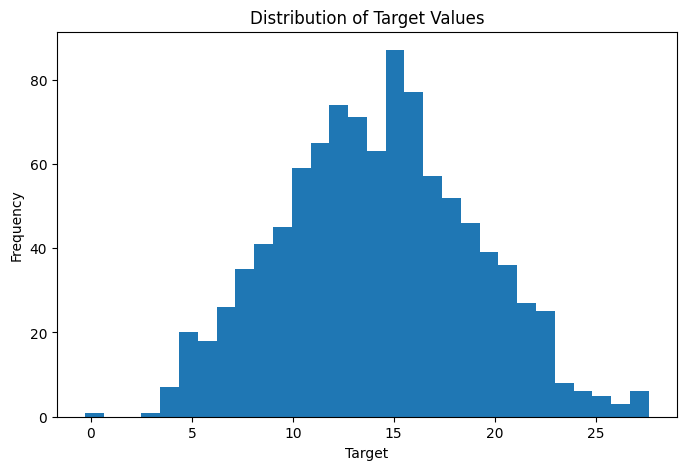

In [31]:

print("Dataset information:")
print(df.info())

print("\nStatistical summary:")
display(df.describe())

plt.figure(figsize=(8, 5))
plt.hist(df["Target"], bins=30)
plt.title("Distribution of Target Values")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.show()


In [32]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

x_scaler = MinMaxScaler()

X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).flatten()

y_test_scaled = y_scaler.transform(
    y_test.reshape(-1, 1)
).flatten()


def tensor_data(X, y):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(
        y.reshape(-1, 1),
        dtype=torch.float32
    )
    return X_tensor, y_tensor


Xtr, ytr = tensor_data(X_train, y_train_scaled)
Xte, yte = tensor_data(X_test, y_test_scaled)

print("Training samples:", len(Xtr))
print("Testing samples:", len(Xte))
print("Number of features:", Xtr.shape[1])


Training samples: 800
Testing samples: 200
Number of features: 10


In [33]:

class DenseRegressor(nn.Module):

    def __init__(self, input_dim=10):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.net(x)


print("Classical MLP model created!")


Classical MLP model created!


In [34]:

class TTLinear(nn.Module):

    def __init__(self, rank=2):
        super().__init__()

        self.G1 = nn.Parameter(
            torch.randn(2, 2, rank) * 0.1
        )

        self.G2 = nn.Parameter(
            torch.randn(rank, 5, 2) * 0.1
        )

        self.bias = nn.Parameter(torch.zeros(4))

    def forward(self, x):

        W = torch.einsum(
            "iar,rjb->ijab",
            self.G1,
            self.G2
        ).reshape(10, 4)

        return x @ W + self.bias


print("Tensor-Train layer created!")


Tensor-Train layer created!


In [35]:

class TTRegressor(nn.Module):

    def __init__(self):
        super().__init__()

        self.tt = TTLinear()

        self.net = nn.Sequential(
            nn.ReLU(),
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.net(self.tt(x))


print("TT + Classical model created!")


TT + Classical model created!


In [36]:

N_QUBITS = 4
N_LAYERS = 2

# Analytic simulation for differentiable training
SHOTS = None

dev = qml.device(
    "default.qubit",
    wires=N_QUBITS,
    shots=SHOTS
)

weight_shapes = {
    "weights": (N_LAYERS, N_QUBITS, 3)
}


@qml.qnode(
    dev,
    interface="torch",
    diff_method="backprop"
)
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(N_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(N_QUBITS)
    )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]


print("Quantum circuit created successfully!")


Quantum circuit created successfully!


In [37]:

class TTVQCRegressor(nn.Module):

    def __init__(self):
        super().__init__()

        self.tt = TTLinear()

        self.vqc = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

        self.output = nn.Linear(4, 1)

    def forward(self, x):

        x = torch.tanh(self.tt(x))

        quantum_outputs = []

        for sample in x:
            q_out = self.vqc(sample)
            quantum_outputs.append(q_out)

        x = torch.stack(quantum_outputs)

        return self.output(x)


print("TT + VQC model created successfully!")


TT + VQC model created successfully!



def train_model(
    model,
    X,
    y,
    epochs=8,
    batch_size=64,
    model_name="Model"
):

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.005
    )

    criterion = nn.MSELoss()

    start_time = time.perf_counter()

    forward_qnode_calls = 0

    model.train()

    for epoch in range(epochs):

        indices = torch.randperm(len(X))
        total_loss = 0

        for start_idx in range(0, len(X), batch_size):

            ids = indices[start_idx:start_idx + batch_size]

            xb = X[ids]
            yb = y[ids]

            optimizer.zero_grad()

            predictions = model(xb)

            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            if model_name == "TT + VQC":
                forward_qnode_calls += len(xb)

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {total_loss:.4f}"
        )

    training_time = time.perf_counter() - start_time

    return model, training_time, forward_qnode_calls


print("Training function created!")


In [38]:

models = {}
training_times = {}
forward_calls = {}

# Model 1: Classical MLP
print("\nTraining Classical MLP...")

models["Classical MLP"], training_times["Classical MLP"], _ = train_model(
    DenseRegressor(10),
    Xtr,
    ytr,
    model_name="Classical MLP"
)

# Model 2: PCA + MLP
print("\nTraining PCA + MLP...")

pca = PCA(n_components=4)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

Xp_train, yp_train = tensor_data(
    X_train_pca,
    y_train_scaled
)

Xp_test, yp_test = tensor_data(
    X_test_pca,
    y_test_scaled
)

models["PCA + MLP"], training_times["PCA + MLP"], _ = train_model(
    DenseRegressor(4),
    Xp_train,
    yp_train,
    model_name="PCA + MLP"
)

# Model 3: TT + Classical
print("\nTraining TT + Classical...")

models["TT + Classical"], training_times["TT + Classical"], _ = train_model(
    TTRegressor(),
    Xtr,
    ytr,
    model_name="TT + Classical"
)

# Model 4: TT + VQC
print("\nTraining TT + VQC...")

models["TT + VQC"], training_times["TT + VQC"], forward_calls["TT + VQC"] = train_model(
    TTVQCRegressor(),
    Xtr,
    ytr,
    epochs=8,
    batch_size=64,
    model_name="TT + VQC"
)

print("\nAll four models trained successfully!")



Training Classical MLP...
Classical MLP | Epoch 1/8 | Loss: 12.4074
Classical MLP | Epoch 2/8 | Loss: 11.9238
Classical MLP | Epoch 3/8 | Loss: 10.5812
Classical MLP | Epoch 4/8 | Loss: 9.2711
Classical MLP | Epoch 5/8 | Loss: 7.8595
Classical MLP | Epoch 6/8 | Loss: 6.9582
Classical MLP | Epoch 7/8 | Loss: 6.3437
Classical MLP | Epoch 8/8 | Loss: 6.0440

Training PCA + MLP...
PCA + MLP | Epoch 1/8 | Loss: 13.5519
PCA + MLP | Epoch 2/8 | Loss: 12.8150
PCA + MLP | Epoch 3/8 | Loss: 13.1656
PCA + MLP | Epoch 4/8 | Loss: 12.9364
PCA + MLP | Epoch 5/8 | Loss: 12.7037
PCA + MLP | Epoch 6/8 | Loss: 12.6667
PCA + MLP | Epoch 7/8 | Loss: 12.9449
PCA + MLP | Epoch 8/8 | Loss: 12.7206

Training TT + Classical...
TT + Classical | Epoch 1/8 | Loss: 13.3583
TT + Classical | Epoch 2/8 | Loss: 13.2124
TT + Classical | Epoch 3/8 | Loss: 13.1355
TT + Classical | Epoch 4/8 | Loss: 13.0000
TT + Classical | Epoch 5/8 | Loss: 13.1104
TT + Classical | Epoch 6/8 | Loss: 12.9553
TT + Classical | Epoch 7/8 | 

In [39]:

def evaluate_model(model, X, y_original):

    model.eval()

    start_time = time.perf_counter()

    with torch.no_grad():
        predictions_scaled = model(X).cpu().numpy()

    inference_time = time.perf_counter() - start_time

    predictions = y_scaler.inverse_transform(
        predictions_scaled
    ).flatten()

    residuals = y_original - predictions

    mae = mean_absolute_error(y_original, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_original, predictions)
    )

    r2 = r2_score(y_original, predictions)

    residual_bias = np.mean(residuals)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Residual Bias": residual_bias,
        "Inference Time (seconds)": inference_time
    }


print("Evaluation function created!")


Evaluation function created!


In [40]:

results = []

for name, model in models.items():

    if name == "PCA + MLP":
        X_eval = Xp_test
    else:
        X_eval = Xte

    metrics = evaluate_model(
        model,
        X_eval,
        y_test
    )

    metrics["Model"] = name
    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "MAE",
        "RMSE",
        "R2",
        "Residual Bias",
        "Inference Time (seconds)"
    ]
]

display(results_df)

results_df.to_csv(
    "Model_Performance_Results.csv",
    index=False
)


,Model,MAE,RMSE,R2,Residual Bias,Inference Time (seconds)
0,Classical MLP,2.413220,3.018783,0.586641,-1.113650,0.000967
1,PCA + MLP,3.772917,4.609945,0.036049,-0.274685,0.000604
2,TT + Classical,3.686572,4.537970,0.065914,-0.268468,0.000871
3,TT + VQC,2.577517,3.142945,0.551939,-0.223502,2.023301


In [22]:

training_sizes = [100, 250, 500, 800]

size_results = []

for size in training_sizes:

    print(f"\nTraining size: {size}")

    # TT + Classical
    classical_model, _, _ = train_model(
        TTRegressor(),
        Xtr[:size],
        ytr[:size],
        epochs=5,
        model_name="TT + Classical"
    )

    classical_metrics = evaluate_model(
        classical_model,
        Xte,
        y_test
    )

    size_results.append({
        "Training Size": size,
        "Model": "TT + Classical",
        "MAE": classical_metrics["MAE"]
    })

    # TT + VQC
    quantum_model, _, _ = train_model(
        TTVQCRegressor(),
        Xtr[:size],
        ytr[:size],
        epochs=3,
        batch_size=32,
        model_name="TT + VQC"
    )

    quantum_metrics = evaluate_model(
        quantum_model,
        Xte,
        y_test
    )

    size_results.append({
        "Training Size": size,
        "Model": "TT + VQC",
        "MAE": quantum_metrics["MAE"]
    })


size_df = pd.DataFrame(size_results)

display(size_df)

size_df.to_csv(
    "Error_vs_Training_Size.csv",
    index=False
)



Training size: 100
TT + Classical | Epoch 1/5 | Loss: 1.9937
TT + Classical | Epoch 2/5 | Loss: 1.9524
TT + Classical | Epoch 3/5 | Loss: 1.8923
TT + Classical | Epoch 4/5 | Loss: 1.9816
TT + Classical | Epoch 5/5 | Loss: 1.9657
TT + VQC | Epoch 1/3 | Loss: 4.2751
TT + VQC | Epoch 2/3 | Loss: 4.7534
TT + VQC | Epoch 3/3 | Loss: 4.5471

Training size: 250
TT + Classical | Epoch 1/5 | Loss: 4.0648
TT + Classical | Epoch 2/5 | Loss: 3.9804
TT + Classical | Epoch 3/5 | Loss: 3.9411
TT + Classical | Epoch 4/5 | Loss: 3.9042
TT + Classical | Epoch 5/5 | Loss: 3.8848
TT + VQC | Epoch 1/3 | Loss: 8.6988
TT + VQC | Epoch 2/3 | Loss: 8.2910
TT + VQC | Epoch 3/3 | Loss: 8.1019

Training size: 500
TT + Classical | Epoch 1/5 | Loss: 7.9726
TT + Classical | Epoch 2/5 | Loss: 7.8084
TT + Classical | Epoch 3/5 | Loss: 7.7056
TT + Classical | Epoch 4/5 | Loss: 7.5792
TT + Classical | Epoch 5/5 | Loss: 7.5334
TT + VQC | Epoch 1/3 | Loss: 15.2309
TT + VQC | Epoch 2/3 | Loss: 15.0333
TT + VQC | Epoch 3/3

,Training Size,Model,MAE
0,100,TT + Classical,3.815505
1,100,TT + VQC,4.193032
2,250,TT + Classical,3.795370
3,250,TT + VQC,3.902643
4,500,TT + Classical,3.843494
5,500,TT + VQC,3.823179
6,800,TT + Classical,3.770147
7,800,TT + VQC,3.870055


In [23]:

example_inputs = torch.zeros(4)

example_weights = torch.zeros(
    N_LAYERS,
    N_QUBITS,
    3
)

circuit_spec = qml.specs(quantum_circuit)(
    example_inputs,
    example_weights
)

resources = circuit_spec["resources"]

resource_df = pd.DataFrame([
    ["Number of Qubits", N_QUBITS],
    ["Quantum Layers", N_LAYERS],
    ["Circuit Depth", resources.depth],
    ["Number of Gates", resources.num_gates],
    ["Shots", "Analytic simulation (None)"],
    ["Training Forward QNode Calls", forward_calls["TT + VQC"]]
], columns=["Resource", "Value"])

display(resource_df)

resource_df.to_csv(
    "Quantum_Resource_Report.csv",
    index=False
)


,Resource,Value
0,Number of Qubits,4
1,Quantum Layers,2
2,Circuit Depth,2
3,Number of Gates,2
4,Shots,Analytic simulation (None)
5,Training Forward QNode Calls,6400


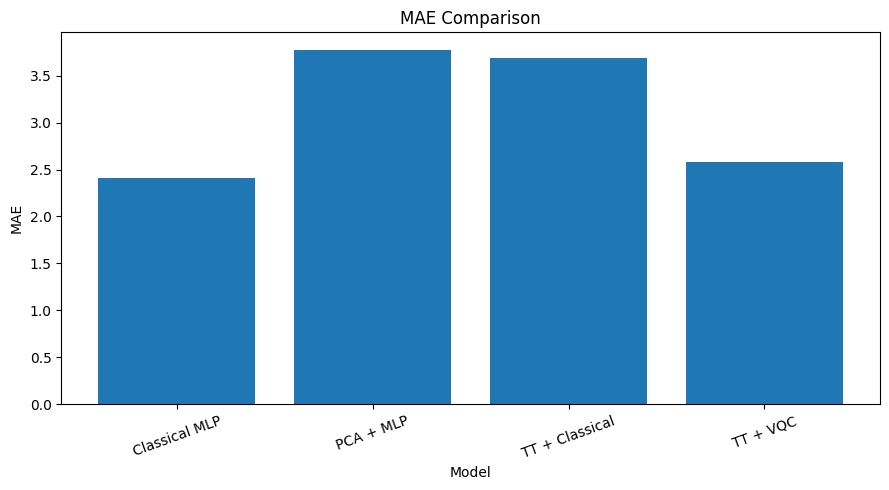

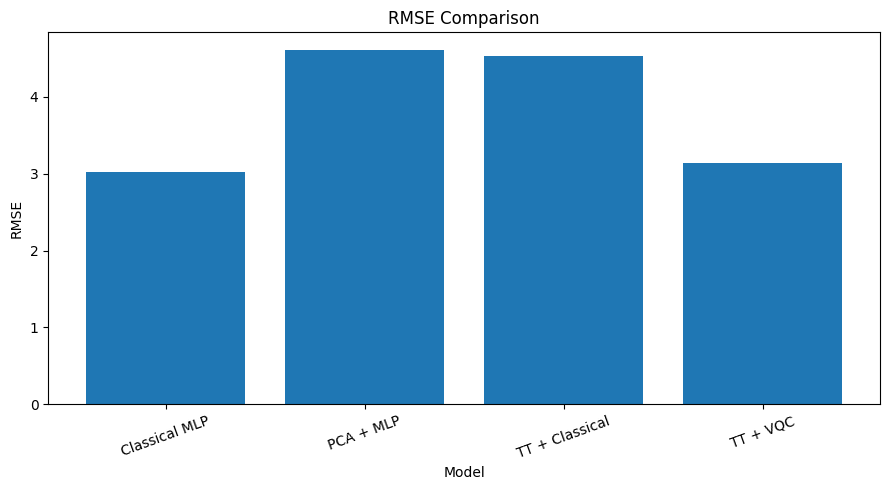

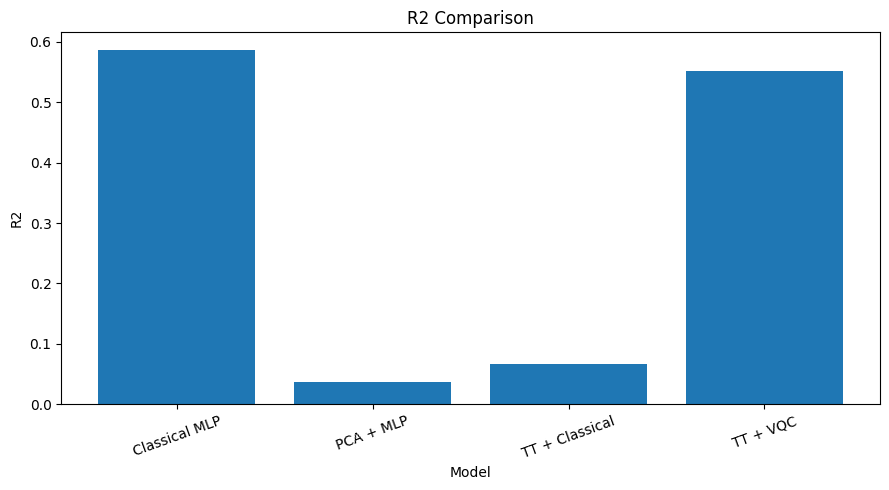

In [24]:

for metric in ["MAE", "RMSE", "R2"]:

    plt.figure(figsize=(9, 5))

    plt.bar(
        results_df["Model"],
        results_df[metric]
    )

    plt.title(f"{metric} Comparison")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


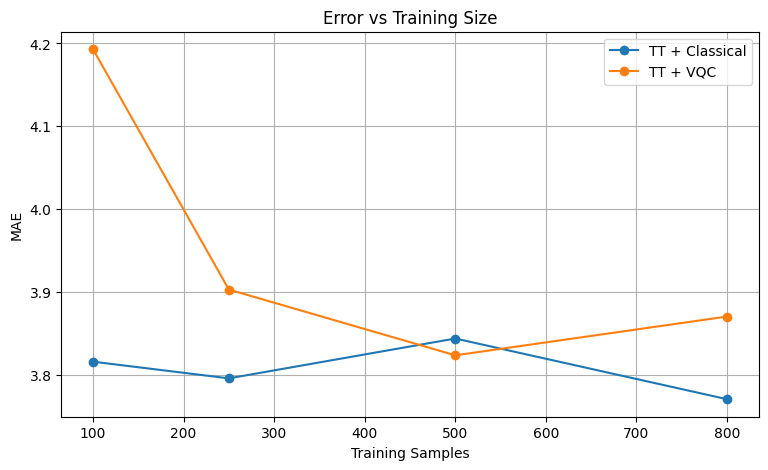

In [25]:

plt.figure(figsize=(9, 5))

for name in size_df["Model"].unique():

    subset = size_df[size_df["Model"] == name]

    plt.plot(
        subset["Training Size"],
        subset["MAE"],
        marker="o",
        label=name
    )

plt.title("Error vs Training Size")
plt.xlabel("Training Samples")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.show()


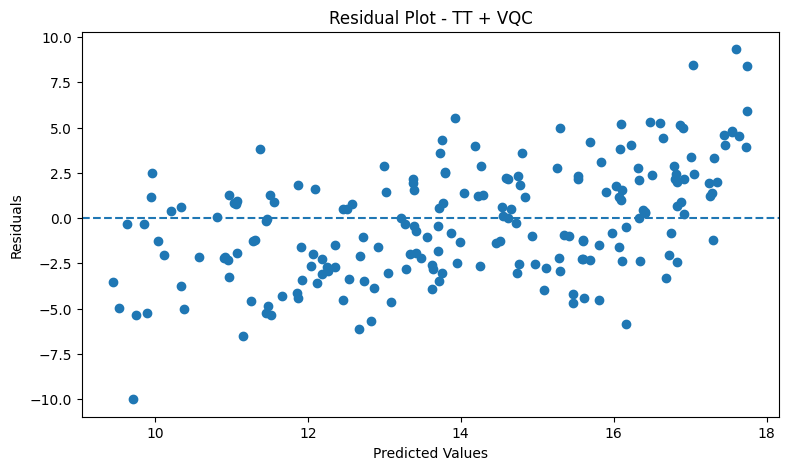

In [26]:

quantum_model = models["TT + VQC"]

quantum_model.eval()

with torch.no_grad():
    predictions_scaled = quantum_model(Xte).numpy()

predictions = y_scaler.inverse_transform(
    predictions_scaled
).flatten()

residuals = y_test - predictions

plt.figure(figsize=(9, 5))

plt.scatter(predictions, residuals)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot - TT + VQC")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()


In [27]:

import zipfile
from google.colab import files

result_files = [
    "Friedman1_VQC_Dataset.csv",
    "Model_Performance_Results.csv",
    "Parameter_Count_Results.csv",
    "Error_vs_Training_Size.csv",
    "Quantum_Resource_Report.csv"
]

with zipfile.ZipFile(
    "TT_VQC_Project_Results.zip",
    "w"
) as zip_file:

    for filename in result_files:
        zip_file.write(filename)

files.download("TT_VQC_Project_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>